# 2.4.- Regresión Lineal con Descenso de Gradiente

En esta práctica vamos a implementar la regresión lineal usando **descenso de gradiente (Gradient Descent, GD)**.  

Objetivos:
- Definir la función de coste (MSE).  
- Calcular el gradiente de los parámetros.  
- Implementar el algoritmo de descenso de gradiente.  
- Analizar el efecto de la tasa de aprendizaje (*learning rate*).  

Recordemos que, en lugar de usar la **ecuación normal**, aquí ajustamos los parámetros $\beta$ de forma iterativa hasta minimizar la función de coste.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

ModuleNotFoundError: No module named 'statsmodels'

## Datos de ejemplo

Generamos un conjunto de datos lineales con ruido gaussiano para simular un caso real.

Ecuación generadora:

$$ y = 4x + 3 + \varepsilon, \quad \varepsilon \sim N(0, 2) $$

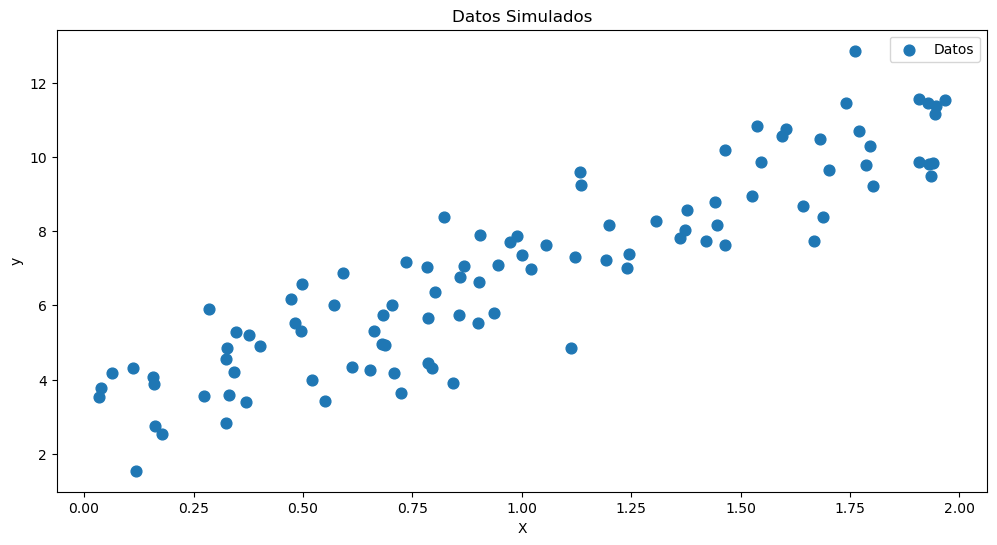

In [ ]:
# Semilla para reproducibilidad
np.random.seed(33)

# Generamos datos lineales con ruido
X = 2 * np.random.rand(100, 1)
y = 4 * X + 3 + np.random.randn(100, 1)

# Visualización
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=60, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Datos Simulados")
plt.legend()
plt.show()

## Función de coste: Error cuadrático medio (MSE)

La regresión lineal busca ajustar los parámetros $\beta_0, \beta_1$ de forma que las predicciones $\hat{y}$ sean lo más cercanas posibles a los valores reales $y$.

La medida de error más común es el **Error Cuadrático Medio (MSE)**:

$$
J = \frac{1}{n} \sum_{i=1}^{n} ( y_i - \hat{y}_i)^2
$$

donde:
- $n$ = número de observaciones.  
- $\hat{y}_i = \beta_0 + \beta_1 x_i$ son las predicciones.  
- $y_i$ son los valores observados.  

El objetivo del descenso de gradiente es **minimizar $J$**.

In [ ]:
# Definimos la función de coste MSE
def compute_cost(X, y, beta):
    """
    Calcula el Error Cuadrático Medio (MSE).

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta: parámetros [beta_0, beta_1]

    Devuelve:
        coste (float)
    """
    n = len(y)
    y_pred = X @ beta
    error = y - y_pred
    cost = (1/n) * np.sum(error**2)
    return cost

# Preparamos X con columna de 1s (intercepto)
X1 = sm.add_constant(X)  # añade columna de 1s
beta_inicial = np.zeros((2, 1))    # matriz de coeficientes: beta_0 = 0, beta_1 = 0

# Calculamos el coste inicial
coste_inicial = compute_cost(X1, y, beta_inicial)
print("Coste inicial (beta_0=0, beta_1=0):", coste_inicial)

Coste inicial (beta_0=0, beta_1=0): 54.97090132216898


## Gradiente de la función de coste

Para minimizar el MSE necesitamos calcular el **gradiente**, es decir, las derivadas parciales de $J(\beta)$ respecto a cada parámetro $\beta_j$.

Recordemos que:

$$
J(\beta) = \frac{1}{n} (X \beta - y)^T (X \beta - y)
$$

El gradiente viene dado por:

$$
\frac{\partial J(\beta)}{\partial \beta} = \frac{1}{n} X^T (X \beta - y)
$$

Esto nos indica en qué dirección (signo) y con qué magnitud debemos actualizar cada $\beta_j$ para acercarnos al mínimo de la fnción de coste.
te.

In [ ]:
def compute_gradient(X, y, beta):
    """
    Calcula el gradiente de la función de coste MSE.

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta: parámetros [beta_0, beta_1]

    Devuelve:
        gradiente (vector 2x1)
    """
    n = len(y)
    gradient = (1/n) * X.T @ (X @ beta - y)
    return gradient

# Gradiente con beta inicial (0,0)
gradiente_inicial = compute_gradient(X1, y, beta_inicial)
print("Gradiente inicial:", gradiente_inicial.ravel())

Gradiente inicial: [-6.95739967 -8.26540396]


## Algoritmo de descenso de gradiente

El algoritmo itera hasta encontrar los parámetros $\beta$ que minimizan la función de coste.

**Regla de actualización:**

$$
\beta \leftarrow \beta - \eta \cdot \frac{\partial J(\beta)}{\partial \beta}
$$

donde:
- $\eta$ es la **tasa de aprendizaje** (*learning rate*).  
- El término $\frac{\partial J(\beta)}{\partial \beta}$ es el gradiente.  

**Pasos del algoritmo:**
1. Elegir valores iniciales para $\beta$.  
2. Calcular el gradiente.  
3. Actualizar los parámetros usando la regla.  
4. Repetir hasta que $\beta$ apenas cambie o se alcance un número máximo de iteraciones.

In [ ]:
def gradient_descent(X, y, beta_inicial, learning_rate, n_iter):
    """
    Descenso de gradiente para regresión lineal.

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta_inicial: valores iniciales de los parámetros
        learning_rate: tasa de aprendizaje (η)
        n_iter: número de iteraciones

    Devuelve:
        beta: parámetros optimizados
        history: lista con el valor del coste en cada iteración
    """
    beta = beta_inicial.copy()
    history = []

    for _ in range(n_iter):
        grad = compute_gradient(X, y, beta)
        beta -= learning_rate * grad
        history.append(compute_cost(X, y, beta))

    return beta, history

# Ejecutamos descenso de gradiente
beta_final, history = gradient_descent(X1, y, beta_inicial, learning_rate=0.1, n_iter=100)

print("Coeficientes finales:")
print("Intercepto (beta_0):", beta_final[0][0])
print("Pendiente (beta_1):", beta_final[1][0])

Coeficientes finales:
Intercepto (beta_0): 2.9591151363876698
Pendiente (beta_1): 4.014790483979907


## Evolución del coste durante el descenso de gradiente

Una forma de comprobar si el algoritmo está funcionando correctamente es observar la evolución del **MSE** a lo largo de las iteraciones.

- Si el learning rate $\eta$ es adecuado, el coste debe **disminuir rápidamente** y luego estabilizarse.  
- Si $\eta$ es demasiado pequeño, el descenso será muy lento.  
- Si $\eta$ es demasiado grande, el coste puede **oscilar o incluso divergir**.

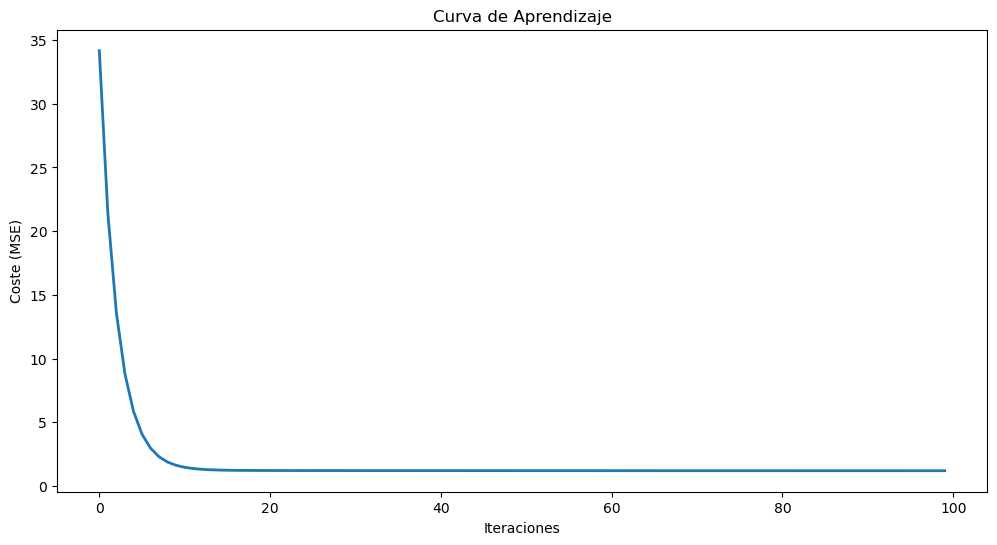

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(history, lw=2)
plt.xlabel("Iteraciones")
plt.ylabel("Coste (MSE)")
plt.title("Curva de Aprendizaje")
plt.show()

## Recta ajustada con los parámetros obtenidos mediante descenso de gradiente

Tras ejecutar el algoritmo, obtenemos los valores optimizados de $\beta_0$ y $\beta_1$.

Podemos representar la **recta ajustada** sobre los datos para comprobar visualmente la calidad del ajuste.

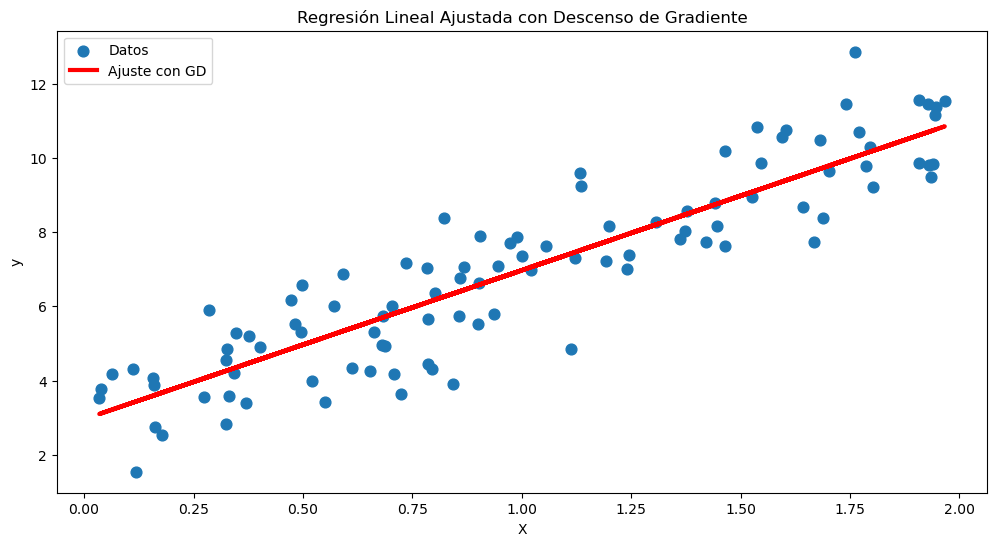

In [ ]:
# Predicciones usando los parámetros finales
y_pred = X1 @ beta_final

# Visualización
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=60, label="Datos")
plt.plot(X, y_pred, color="red", lw=3, label="Ajuste con GD")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión Lineal Ajustada con Descenso de Gradiente")
plt.legend()
plt.show()